# EDA и RFM-сегментация клиентов Т-Банка

**Цель:** исследовать транзакционное поведение клиентов, выявить ключевые паттерны (распределение сумм, категории, сезонность) и провести RFM-сегментацию для выделения групп клиентов по давности, частоте и сумме покупок.

**Данные:** `data/processed/transactions_clean.csv` (14,0 млн транзакций, 50 000 пользователей, 2019-01-01 – 2020-02-29).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Настройки визуализации
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

# Пути
PROCESSED_PATH = Path('../data/processed/transactions_clean.csv')
IMAGES_EDA = Path('../images/eda')

# Загрузка данных с парсингом даты
df = pd.read_csv(PROCESSED_PATH, parse_dates=['transaction_dttm'])
print(f"Загружено: {df.shape[0]:,} строк, {df.shape[1]} колонок")

Загружено: 14,036,337 строк, 13 колонок


## 1. Общая статистика

Базовые метрики: количество транзакций, пользователей, средний чек, период.

In [2]:
total_txn = len(df)
total_users = df['party_rk'].nunique()
avg_check = df['transaction_amt'].mean()
median_check = df['transaction_amt'].median()
period_start = df['transaction_dttm'].min().date()
period_end = df['transaction_dttm'].max().date()

print(f"Всего транзакций: {total_txn:,}")
print(f"Уникальных пользователей: {total_users:,}")
print(f"Средний чек: {avg_check:,.0f} ₽")
print(f"Медианный чек: {median_check:,.0f} ₽")
print(f"Период: {period_start} – {period_end}")

Всего транзакций: 14,036,337
Уникальных пользователей: 50,000
Средний чек: 2,751 ₽
Медианный чек: 394 ₽
Период: 2019-01-01 – 2020-02-29


**Вывод:** средний чек (2 751 ₽) почти в 7 раз выше медианного (394 ₽) — распределение сильно скошено вправо, что типично для транзакционных данных. Для описания рынка опираемся на медиану.

## 2. Распределение сумм транзакций

Суммы транзакций сильно скошены вправо — построим гистограмму в логарифмической шкале, чтобы увидеть структуру.

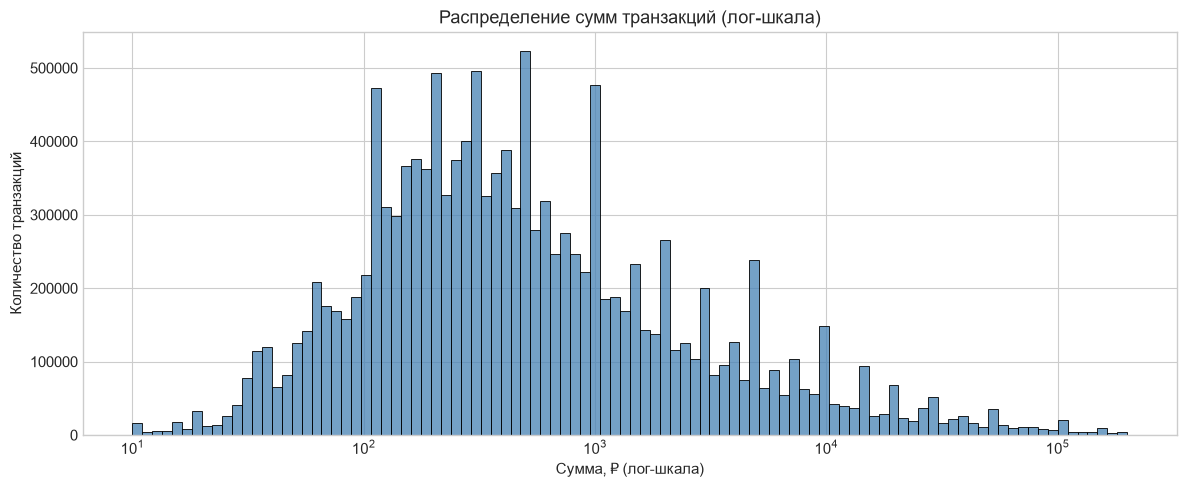

In [3]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.histplot(df['transaction_amt'], bins=100, log_scale=True, ax=ax, color='steelblue')
ax.set_title('Распределение сумм транзакций (лог-шкала)')
ax.set_xlabel('Сумма, ₽ (лог-шкала)')
ax.set_ylabel('Количество транзакций')
plt.tight_layout()
plt.savefig(IMAGES_EDA / '01_amount_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

**Вывод:** распределение сумм логнормальное: основная масса транзакций — до 1 000 ₽, но есть длинный хвост крупных платежей.

## 3. Топ категорий по количеству транзакций

Категории анонимизированы (числовые коды), но можно увидеть, какие встречаются чаще всего.

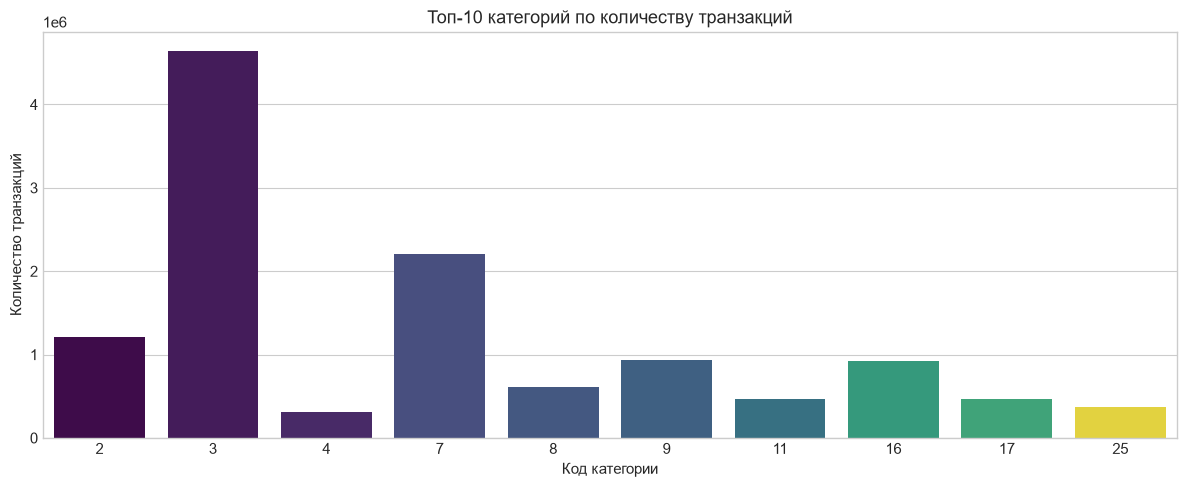

In [4]:
top_categories = df['category'].value_counts().head(10)

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(x=top_categories.index, y=top_categories.values, ax=ax, hue=top_categories.index, palette='viridis', legend=False)
ax.set_title('Топ-10 категорий по количеству транзакций')
ax.set_xlabel('Код категории')
ax.set_ylabel('Количество транзакций')
plt.tight_layout()
plt.savefig(IMAGES_EDA / '02_top_categories.png', dpi=150, bbox_inches='tight')
plt.show()

**Вывод:** категория 3 — самая массовая, далее 7 и 2. Категории анонимизированы, но структура показывает, что несколько категорий доминируют по количеству операций.

## 4. Топ типов транзакций

`transaction_type_desc` — тип транзакции (также анонимизирован).

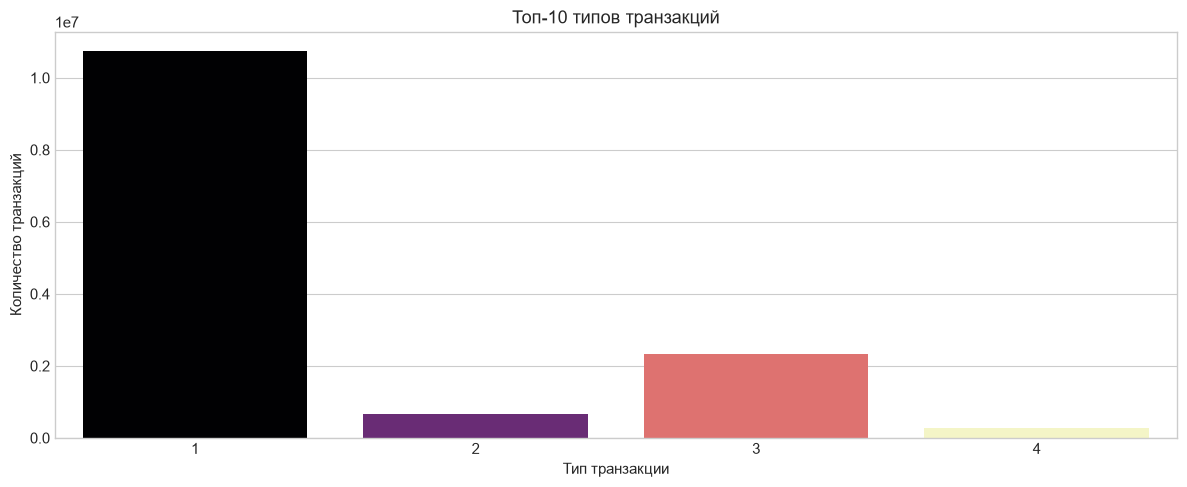

In [5]:
top_types = df['transaction_type_desc'].value_counts().head(10)

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(x=top_types.index, y=top_types.values, ax=ax, hue=top_types.index, palette='magma', legend=False)
ax.set_title('Топ-10 типов транзакций')
ax.set_xlabel('Тип транзакции')
ax.set_ylabel('Количество транзакций')
plt.tight_layout()
plt.savefig(IMAGES_EDA / '03_top_transaction_types.png', dpi=150, bbox_inches='tight')
plt.show()

**Вывод:** тип 1 — абсолютный лидер (покупки), остальные типы представлены значительно реже.

## 5. Динамика транзакций по месяцам

Смотрим на сезонность и тренды: сколько транзакций и на какую сумму было в каждом месяце.

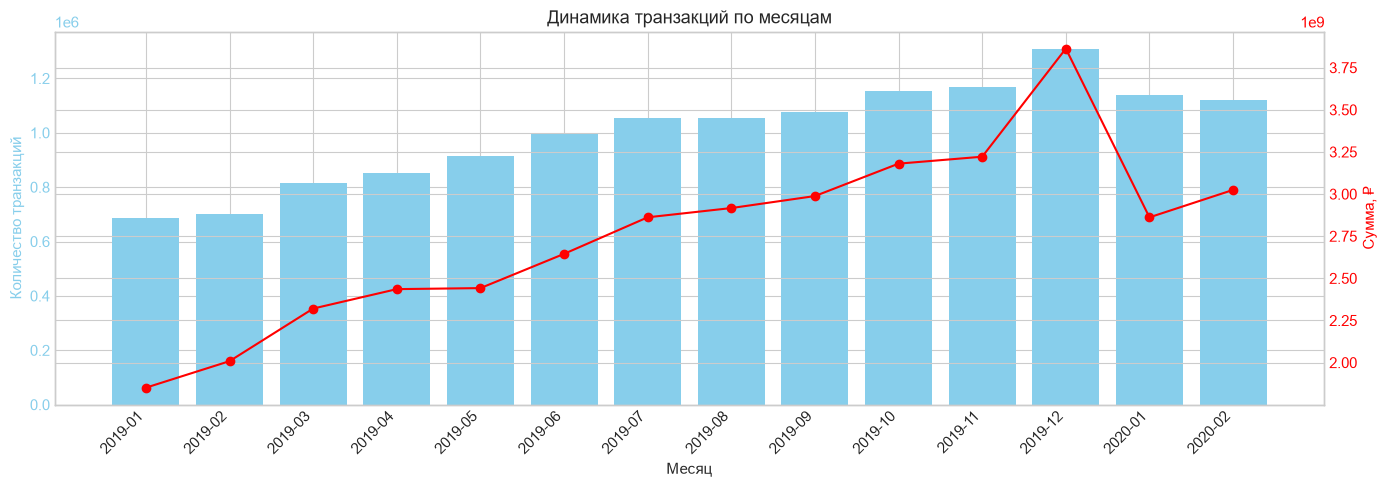

In [6]:
monthly = df.groupby(df['transaction_dttm'].dt.to_period('M')).agg(
    txn_count=('transaction_amt', 'count'),
    total_amount=('transaction_amt', 'sum')
).reset_index()
monthly['transaction_dttm'] = monthly['transaction_dttm'].astype(str)

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.bar(monthly['transaction_dttm'], monthly['txn_count'], color='skyblue', label='Количество транзакций')
ax1.set_xlabel('Месяц')
ax1.set_ylabel('Количество транзакций', color='skyblue')
ax1.tick_params(axis='y', labelcolor='skyblue')
ax1.set_xticks(range(len(monthly)))
ax1.set_xticklabels(monthly['transaction_dttm'], rotation=45, ha='right')

ax2 = ax1.twinx()
ax2.plot(monthly['transaction_dttm'], monthly['total_amount'], color='red', marker='o', label='Сумма, ₽')
ax2.set_ylabel('Сумма, ₽', color='red')
ax2.tick_params(axis='y', labelcolor='red')

ax1.set_title('Динамика транзакций по месяцам')
fig.tight_layout()
plt.savefig(IMAGES_EDA / '04_monthly_trend.png', dpi=150, bbox_inches='tight')
plt.show()

**Вывод:** пик транзакций — декабрь 2019, что связано с предновогодними покупками. В январе 2020 наблюдается резкий спад активности после праздников.

## 6. Транзакции по дням недели

Проверяем, есть ли разница между буднями и выходными.

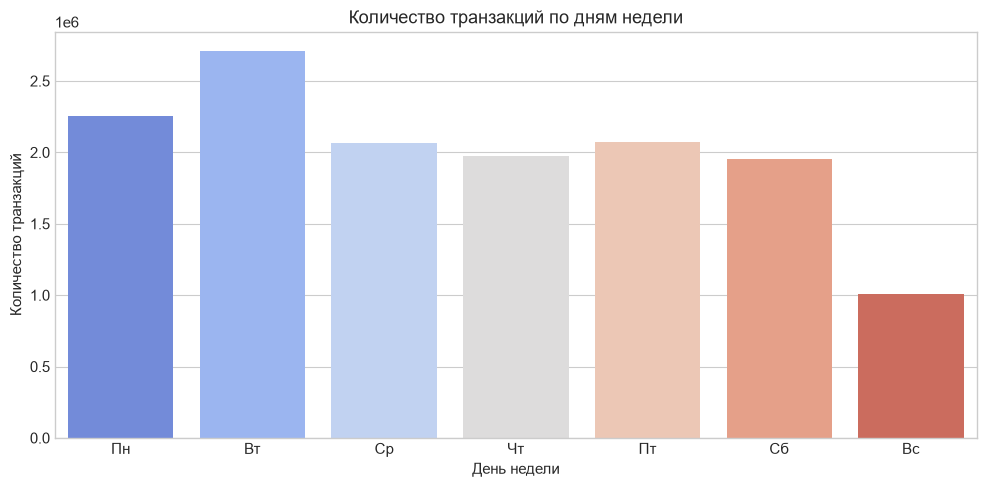

In [7]:
weekday_names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
weekday_counts = df['day_of_week'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=weekday_names, y=weekday_counts.values, ax=ax, hue=weekday_names, palette='coolwarm', legend=False)
ax.set_title('Количество транзакций по дням недели')
ax.set_xlabel('День недели')
ax.set_ylabel('Количество транзакций')
plt.tight_layout()
plt.savefig(IMAGES_EDA / '05_weekday_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

**Вывод:** количество транзакций в будни выше, чем в выходные. Пик активности приходится на вторник, минимум — на воскресенье.

## 7. RFM-сегментация

**RFM** — классический метод сегментации клиентов:
- **Recency (R):** сколько дней прошло с последней транзакции клиента до максимальной даты в датасете.
- **Frequency (F):** количество транзакций клиента.
- **Monetary (M):** суммарная сумма трат клиента.

Каждому клиенту присваиваем оценку от 1 до 5 по каждому параметру (5 — лучший результат) и формируем сегменты.

In [8]:
# Максимальная дата в датасете (точка отсчёта для Recency)
snapshot_date = df['transaction_dttm'].max() + pd.Timedelta(days=1)

rfm = df.groupby('party_rk').agg(
    recency=('transaction_dttm', lambda x: (snapshot_date - x.max()).days),
    frequency=('transaction_amt', 'count'),
    monetary=('transaction_amt', 'sum')
).reset_index()

print(f"RFM-таблица: {rfm.shape[0]:,} клиентов")
rfm.head()

RFM-таблица: 50,000 клиентов


,party_rk,recency,frequency,monetary
0,1,1,828,3181737.0
1,2,1,539,250979.0
2,3,1,919,4637115.0
3,4,1,999,2276923.0
4,5,1,638,1575196.0


**Вывод:** RFM-метрики рассчитаны для 50 000 клиентов. В первых строках таблицы видно, что у самых активных клиентов frequency достигает 999 транзакций, а monetary — нескольких миллионов рублей.

In [9]:
# Оценки по квантилям (5 — лучший результат)
# Используем rank(method='first'), чтобы разорвать связи между одинаковыми значениями и избежать ошибки
rfm['r_score'] = pd.qcut(rfm['recency'].rank(method='first'), q=5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['f_score'] = pd.qcut(rfm['frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['m_score'] = pd.qcut(rfm['monetary'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm['rfm_score'] = rfm['r_score'].astype(str) + rfm['f_score'].astype(str) + rfm['m_score'].astype(str)

rfm.head()

,party_rk,recency,frequency,monetary,r_score,f_score,m_score,rfm_score
0,1,1,828,3181737.0,5,5,5,555
1,2,1,539,250979.0,5,5,3,553
2,3,1,919,4637115.0,5,5,5,555
3,4,1,999,2276923.0,5,5,5,555
4,5,1,638,1575196.0,5,5,5,555


**Вывод:** оценки присвоены по квантилям, что обеспечивает равномерное распределение клиентов по каждой шкале.

## 8. Сегментация клиентов

На основе RFM-оценок выделяем группы:
- **Чемпионы** — R=5, F=5, M=5 (самые лояльные и ценные).
- **Лояльные** — высокие оценки по всем параметрам.
- **Перспективные** — недавние, но ещё не частые.
- **Спящие** — давно не покупали.
- **Потерянные** — низкие оценки по всем параметрам.

In [10]:
def segment(row):
    r, f, m = row['r_score'], row['f_score'], row['m_score']
    if r >= 4 and f >= 4 and m >= 4:
        return 'Чемпионы'
    elif r >= 3 and f >= 3:
        return 'Лояльные'
    elif r >= 3 and f < 3:
        return 'Перспективные'
    elif r < 3 and f >= 3:
        return 'Спящие'
    else:
        return 'Потерянные'

rfm['segment'] = rfm.apply(segment, axis=1)
segment_counts = rfm['segment'].value_counts()
print(segment_counts)

segment
Потерянные       13088
Лояльные         11666
Чемпионы         11422
Спящие            6912
Перспективные     6912
Name: count, dtype: int64


**Вывод:** наибольшая группа — «Потерянные» (13 088 клиентов), затем «Лояльные» (11 666) и «Чемпионы» (11 422). «Спящие» и «Перспективные» — по 6 912 клиентов.

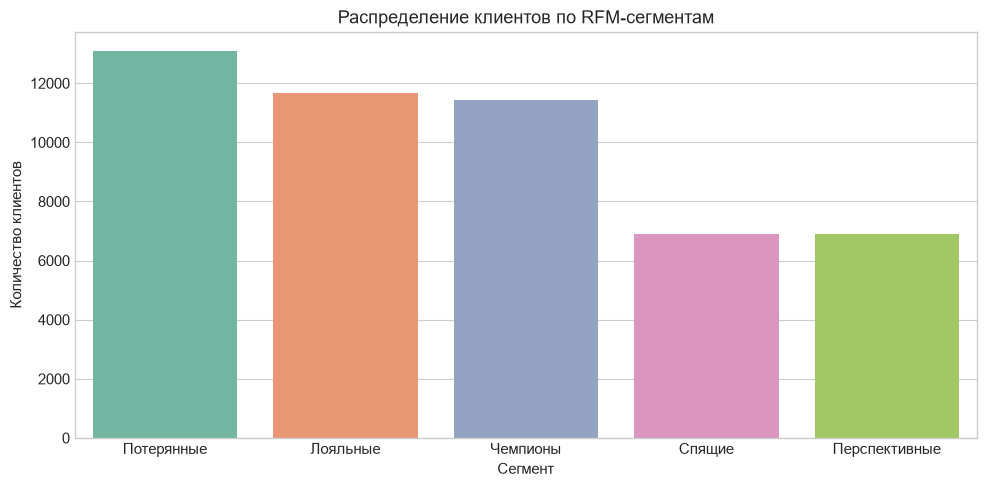

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=segment_counts.index, y=segment_counts.values, ax=ax, hue=segment_counts.index, palette='Set2', legend=False)
ax.set_title('Распределение клиентов по RFM-сегментам')
ax.set_xlabel('Сегмент')
ax.set_ylabel('Количество клиентов')
plt.tight_layout()
plt.savefig(IMAGES_EDA / '06_rfm_segments.png', dpi=150, bbox_inches='tight')
plt.show()

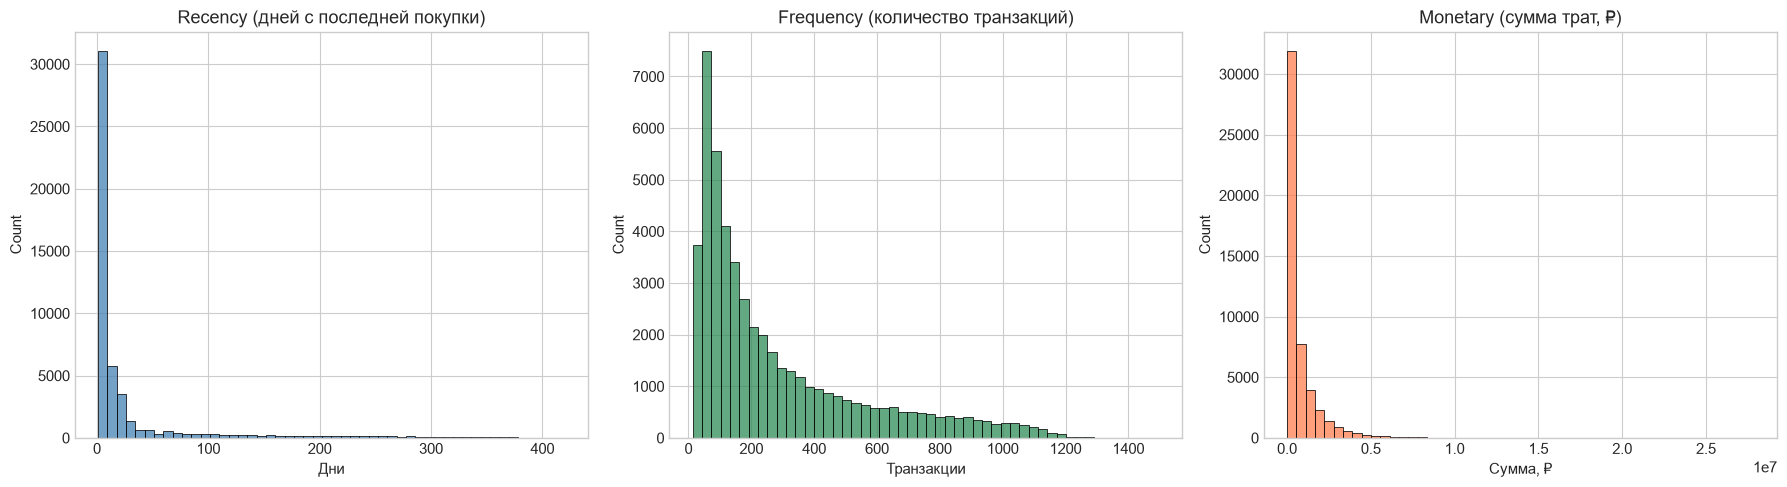

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(rfm['recency'], bins=50, ax=axes[0], color='steelblue')
axes[0].set_title('Recency (дней с последней покупки)')
axes[0].set_xlabel('Дни')

sns.histplot(rfm['frequency'], bins=50, ax=axes[1], color='seagreen')
axes[1].set_title('Frequency (количество транзакций)')
axes[1].set_xlabel('Транзакции')

sns.histplot(rfm['monetary'], bins=50, ax=axes[2], color='coral')
axes[2].set_title('Monetary (сумма трат, ₽)')
axes[2].set_xlabel('Сумма, ₽')

plt.tight_layout()
plt.savefig(IMAGES_EDA / '07_rfm_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

**Вывод:** распределения R, F, M сильно скошены, поэтому для кластеризации потребуется логарифмирование и стандартизация.

## 9. Сохранение RFM-таблицы

Сохраняем результаты для дальнейшей кластеризации и загрузки в PostgreSQL.

In [13]:
rfm_path = Path('../data/processed/rfm_segments.csv')
rfm.to_csv(rfm_path, index=False)
print(f"RFM-таблица сохранена в {rfm_path}")

RFM-таблица сохранена в ..\data\processed\rfm_segments.csv


## 10. Выводы

- **Объём:** 14,0 млн транзакций, 50 000 клиентов, период 2019-01-01 – 2020-02-29.
- **Средний чек:** ~2 751 ₽, медианный — ~394 ₽ (сильная правосторонняя асимметрия).
- **Сезонность:** пик транзакций приходится на декабрь 2019 (предновогодний период).
- **RFM-сегменты:** наибольшая группа — «Потерянные» (26,2%), затем «Лояльные» (23,3%) и «Чемпионы» (22,8%). «Спящие» и «Перспективные» — по 13,8%.
- **Распределения R, F, M** сильно скошены — для кластеризации потребуется логарифмирование или стандартизация.